# BiciMAD infrastructure evolution

This notebook follows how the physical BiciMAD network changed. It starts with the number of bicycles in the network, then the total time they spent in use, then the number of docks, then the number of bicycles per dock, then the number of stations EMT listed in each status snapshot, then the share of their time spent in use.


## 0. Setup


In [1]:
from __future__ import annotations

import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib.ticker import MaxNLocator

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.titlesize"] = 12

HERE = Path.cwd().resolve()
ROOT = HERE
for _candidate in (HERE, *HERE.parents):
    if (_candidate / "src" / "bicimad" / "__init__.py").is_file():
        ROOT = _candidate
        break
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)

from bicimad.config import (
    MADRID_TZ,
    ProjectConfig,
    _month_from_stem,
    discover_months,
    discover_status_files,
    discover_trip_files,
)
from bicimad.download import ensure_status_files, ensure_trip_files
from bicimad.ingest import (
    count_trips_in_progress,
    load_snapshot_station_counts,
    snapshot_dock_capacity,
    snapshot_docked_bikes,
    trip_intervals,
)
from bicimad.utilization import daily_presence_utilization

cfg = ProjectConfig()
print("project root:", cfg.root)


project root: C:\Users\jejoz\Coding\TFG\v1


## 1. Bicycles in the network over time

A bicycle counts as in the network when it is docked at a station or out on a trip. At snapshot time $t$

$$
B(t) = \sum_{s} d_s(t) + \bigl|\{\text{trips in progress at } t\}\bigr|.
$$

Here $d_s(t)$ is `dock_bikes` at station $s$ in the snapshot. The sum covers every listed station, including a station with `no_available` equal to 1. A missing `dock_bikes` counts as zero. A trip is in progress when its start is at or before $t$ and its end is after $t$. A trip with no end time is left out.

The plotted value is the median of $B(t)$ on each calendar day in Europe/Madrid. A day with no snapshot is a gap in the line. The code below downloads any status file or trip file that is not already on disk, then keeps the months present in both archives. Each month is counted on its own, and that month's trips are dropped before the next month is read.


EMT 2017: listing https://media.emtmadrid.es/-HoGTStPZeC


EMT 2017: archive has no station-status files.


EMT 2018: listing https://media.emtmadrid.es/-9iZNUjrjri


EMT 2019: listing https://media.emtmadrid.es/-WNgfSj2ZvC


EMT 2020: listing https://media.emtmadrid.es/-rkuBymuFJX


EMT 2021: listing https://media.emtmadrid.es/-BRk4rTaAdV


... (61 outputs left out)

2022-09: cached, 717 snapshots

2022-10: cached, 739 snapshots

2022-11: cached, 717 snapshots


2022-12: cached, 725 snapshots

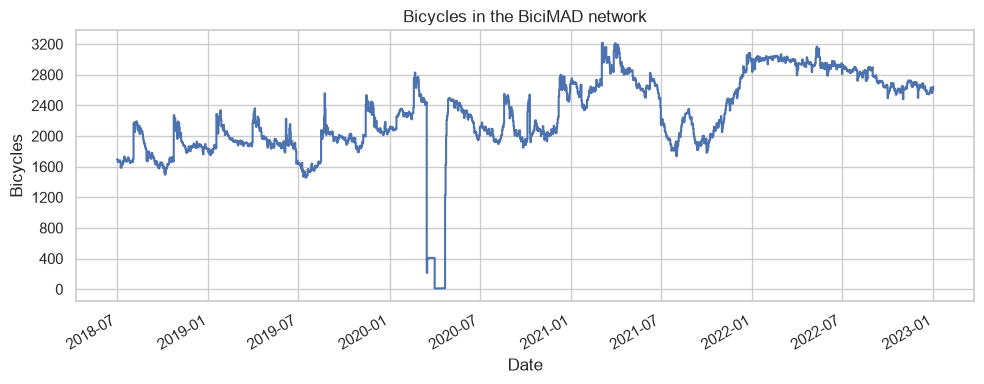

months used: 54 (2018-07 to 2022-12)
months: 2018-07, 2018-08, 2018-09, 2018-10, 2018-11, 2018-12, 2019-01, 2019-02, 2019-03, 2019-04, 2019-05, 2019-06, 2019-07, 2019-08, 2019-09, 2019-10, 2019-11, 2019-12, 2020-01, 2020-02, 2020-03, 2020-04, 2020-05, 2020-06, 2020-07, 2020-08, 2020-09, 2020-10, 2020-11, 2020-12, 2021-01, 2021-02, 2021-03, 2021-04, 2021-05, 2021-06, 2021-07, 2021-08, 2021-09, 2021-10, 2021-11, 2021-12, 2022-01, 2022-02, 2022-03, 2022-04, 2022-05, 2022-06, 2022-07, 2022-08, 2022-09, 2022-10, 2022-11, 2022-12
months inside that span without both files: none
snapshots: 39,252
first day 2018-07-01: 1695.0
last day 2023-01-01: 2643.0
minimum 10.0 on 2020-04-01
maximum 3217.5 on 2021-03-05


In [2]:
import json

status_report = ensure_status_files(cfg)
trip_report = ensure_trip_files(cfg)
print("status files:", status_report["action"].value_counts().to_dict())
print("trip files:", trip_report["action"].value_counts().to_dict())

months = discover_months(cfg)["both"]
if not months:
    raise RuntimeError("No month has both a status file and a trip file.")
status_files = discover_status_files(cfg)
trip_files = discover_trip_files(cfg)
missing_names = [
    path.name
    for path in sorted(cfg.trips_raw.iterdir())
    if path.is_file() and _month_from_stem(path.stem) is None
]
if missing_names:
    raise RuntimeError("Trip files with no month key: " + ", ".join(missing_names))

cache_dir = cfg.processed_dir / "infrastructure" / "bicycle_snapshots"
cache_dir.mkdir(parents=True, exist_ok=True)

frames = []
for month in months:
    status_path = status_files[month]
    trip_path = trip_files[month]
    cache = cache_dir / f"{month}.parquet"
    manifest_path = cache_dir / f"{month}.manifest.json"
    manifest = {
        "status": {"file": status_path.name, "bytes": status_path.stat().st_size},
        "trips": {"file": trip_path.name, "bytes": trip_path.stat().st_size},
    }
    if cache.is_file() and manifest_path.is_file():
        saved = json.loads(manifest_path.read_text(encoding="utf-8"))
        if saved == manifest:
            frame = pd.read_parquet(cache)
            frames.append(frame)
            print(f"{month}: cached, {len(frame):,} snapshots", flush=True)
            continue
    print(f"{month}: counting {status_path.name} and {trip_path.name}", flush=True)
    docked = snapshot_docked_bikes(status_path)
    start_ns, end_ns = trip_intervals(trip_path)
    riding = count_trips_in_progress(
        docked["ts"].astype("int64").to_numpy(),
        start_ns,
        end_ns,
    )
    frame = docked[["ts", "n_docked"]].copy()
    frame["n_riding"] = riding
    frame["n_bikes"] = frame["n_docked"].to_numpy() + riding
    frame["month"] = month
    frame.to_parquet(cache, index=False)
    manifest_path.write_text(json.dumps(manifest), encoding="utf-8")
    print(f"{month}: {len(frame):,} snapshots, {len(start_ns):,} trips", flush=True)
    del docked, start_ns, end_ns, riding
    frames.append(frame)

bikes = pd.concat(frames, ignore_index=True)


def _as_count(series: pd.Series) -> pd.Series:
    values = pd.to_numeric(series, errors="coerce")
    if values.dropna().empty or values.dropna().mod(1).eq(0).all():
        return values.round().astype("Int64")
    return values


local_day = bikes["ts"].dt.tz_convert(MADRID_TZ).dt.floor("D")
bike_daily = (
    bikes.assign(date=local_day)
    .groupby("date", as_index=False)
    .agg(n_bikes=("n_bikes", "median"))
    .sort_values("date")
    .reset_index(drop=True)
)
bike_daily["n_bikes"] = _as_count(bike_daily["n_bikes"])

calendar = pd.date_range(
    bike_daily["date"].min(), bike_daily["date"].max(), freq="D", tz=MADRID_TZ
)
bike_plot = bike_daily.set_index("date").reindex(calendar)

fig, ax = plt.subplots()
ax.step(bike_plot.index.tz_localize(None), bike_plot["n_bikes"], where="post")
ax.set_title("Bicycles in the BiciMAD network")
ax.set_xlabel("Date")
ax.set_ylabel("Bicycles")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

present = bike_plot["n_bikes"].dropna()
span = pd.period_range(months[0], months[-1], freq="M")
inside_missing = [str(period) for period in span if str(period) not in set(months)]
print(f"months used: {len(months)} ({months[0]} to {months[-1]})")
print("months:", ", ".join(months))
print("months inside that span without both files:", inside_missing or "none")
print(f"snapshots: {len(bikes):,}")
print(f"first day {present.index[0].strftime('%Y-%m-%d')}: {present.iloc[0]}")
print(f"last day {present.index[-1].strftime('%Y-%m-%d')}: {present.iloc[-1]}")
print(f"minimum {present.min()} on {present.idxmin().strftime('%Y-%m-%d')}")
print(f"maximum {present.max()} on {present.idxmax().strftime('%Y-%m-%d')}")


The chart below is the same daily median of $B(t)$ from July 2019 through January 2020.


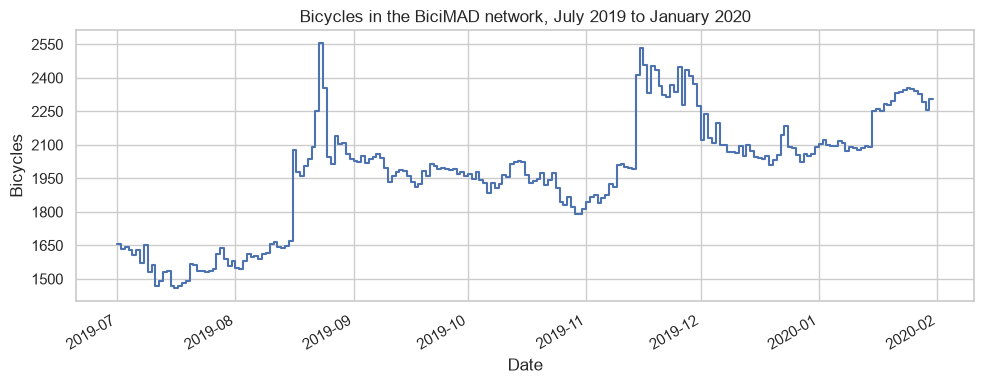

plotted days: 215
gap days: none
first day 2019-07-01: 1655.5
last day 2020-01-31: 2304.0
minimum 1457.5 on 2019-07-16
maximum 2557.0 on 2019-08-23


In [2]:
import json

months = [
    month
    for month in discover_months(cfg)["both"]
    if "2019-07" <= month <= "2020-01"
]
expected = [str(period) for period in pd.period_range("2019-07", "2020-01", freq="M")]
if months != expected:
    raise RuntimeError(
        "July 2019 through January 2020 is missing a status file or a trip file: "
        + ", ".join(month for month in expected if month not in set(months))
    )
status_files = discover_status_files(cfg)
trip_files = discover_trip_files(cfg)
cache_dir = cfg.processed_dir / "infrastructure" / "bicycle_snapshots"

frames = []
for month in months:
    status_path = status_files[month]
    trip_path = trip_files[month]
    cache = cache_dir / f"{month}.parquet"
    manifest_path = cache_dir / f"{month}.manifest.json"
    manifest = {
        "status": {"file": status_path.name, "bytes": status_path.stat().st_size},
        "trips": {"file": trip_path.name, "bytes": trip_path.stat().st_size},
    }
    if not cache.is_file() or not manifest_path.is_file():
        raise RuntimeError(
            f"{month}: bicycle snapshot cache is missing. Run the bicycle section first."
        )
    saved = json.loads(manifest_path.read_text(encoding="utf-8"))
    if saved != manifest:
        raise RuntimeError(
            f"{month}: bicycle snapshot cache is stale. Run the bicycle section first."
        )
    frames.append(pd.read_parquet(cache, columns=["ts", "n_bikes"]))

bikes = pd.concat(frames, ignore_index=True)


def _as_count(series: pd.Series) -> pd.Series:
    values = pd.to_numeric(series, errors="coerce")
    if values.dropna().empty or values.dropna().mod(1).eq(0).all():
        return values.round().astype("Int64")
    return values


local_day = bikes["ts"].dt.tz_convert(MADRID_TZ).dt.floor("D")
bike_daily = (
    bikes.assign(date=local_day)
    .groupby("date", as_index=False)
    .agg(n_bikes=("n_bikes", "median"))
    .sort_values("date")
    .reset_index(drop=True)
)
bike_daily["n_bikes"] = _as_count(bike_daily["n_bikes"])

start = pd.Timestamp("2019-07-01", tz=MADRID_TZ)
end = pd.Timestamp("2020-01-31", tz=MADRID_TZ)
calendar = pd.date_range(start, end, freq="D", tz=MADRID_TZ)
zoom = bike_daily.set_index("date")["n_bikes"].reindex(calendar)

fig, ax = plt.subplots(figsize=(10, 4))
ax.step(zoom.index.tz_localize(None), zoom, where="post")
ax.set_title("Bicycles in the BiciMAD network, July 2019 to January 2020")
ax.set_xlabel("Date")
ax.set_ylabel("Bicycles")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

present = zoom.dropna()
gaps = [ts.strftime("%Y-%m-%d") for ts in zoom.index[zoom.isna()]]
print(f"plotted days: {len(present):,}")
print("gap days:", ", ".join(gaps) if gaps else "none")
print(f"first day {present.index[0].strftime('%Y-%m-%d')}: {present.iloc[0]}")
print(f"last day {present.index[-1].strftime('%Y-%m-%d')}: {present.iloc[-1]}")
print(f"minimum {present.min()} on {present.idxmin().strftime('%Y-%m-%d')}")
print(f"maximum {present.max()} on {present.idxmax().strftime('%Y-%m-%d')}")


The daily median of $B(t)$ starts at 1,695 bicycles on 1 July 2018 and sits close to 2,500 in February 2020. On 16 March 2020 the docked count collapses. From 18 March through 31 March the median stays at 408: about 10 bicycles are still reported in the docks and about 398 are recorded as out on a trip in the March file. From 1 April through 18 April the median is 10, the bicycles still listed in the docks. The count climbs from 22 April and is back near 2,500 at the end of that month.

The highest daily median is 3,217.5 on 5 March 2021. A half bicycle is a day whose snapshots were split between two counts, so the median lies halfway between them. Through 2022 the median stays mostly between 2,600 and 3,000. The last point is 2,643 on 1 January 2023, from the single snapshot at the end of the December 2022 status file.

The series uses the 54 months that have both a status file and a trip file, July 2018 through December 2022. No calendar day from 1 July 2018 through 1 January 2023 is missing a snapshot.


### Why the line spikes through May 2021

Through May 2021 the trip files are JSON, and every start is stored in `unplug_hourTime` at the top of the hour no matter the actual minute (`HH:00:00`). $B(t)$ adds the docked count to the trips in progress. In the minutes after the hour a bicycle can still sit in `dock_bikes` and already count as in progress, so a snapshot adds that hour's departures on top of a docked count that has barely moved. Later in the hour the short trips expire and the total falls. The daily median inherits those jumps.

On average, the time interval between station snapshots about 2 seconds greater than the hour. If a given day's first snapshot timestamp is `00:00:00`, its last snapshot timestamp will be around `23:00:36`. In this case, since the state of the stations is captured early in the hour, and trips in progress start at `HH:00:00`, bikes that belong in the snapshot are also being counted as being on a trip.


2018-07: 382,929 trips


2018-08: 274,121 trips


2018-09: 436,681 trips


2018-10: 385,450 trips


2018-11: 300,131 trips


2018-12: 273,272 trips


... (25 outputs left out)

2021-02: 262,101 trips


2021-03: 360,683 trips


2021-04: 341,058 trips


2021-05: 414,248 trips


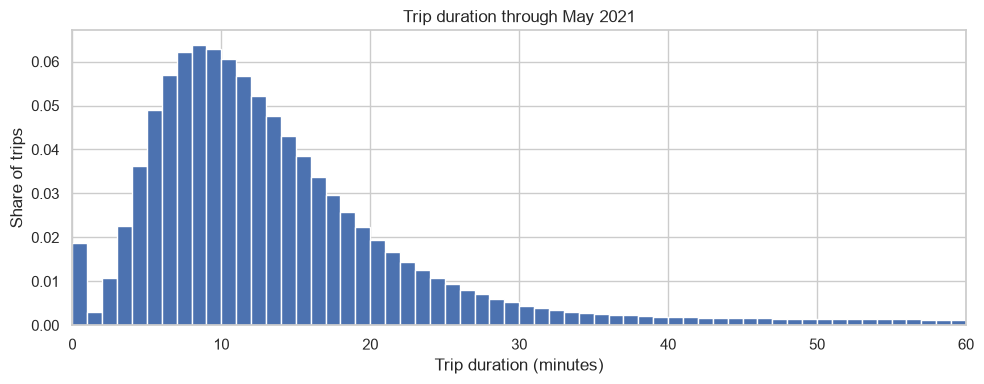

trips: 10,892,185
median: 11.9 minutes
longer than 60 minutes: 3.6%
still in progress at 36 seconds: 98.2%
still in progress at 1 minute: 98.1%
still in progress at 4 minutes: 94.4%
still in progress at 15 minutes: 35.3%


In [2]:
import re

import numpy as np

months = [
    month
    for month in discover_months(cfg)["both"]
    if "2018-07" <= month <= "2021-05"
]
expected = [str(period) for period in pd.period_range("2018-07", "2021-05", freq="M")]
if months != expected:
    missing = [month for month in expected if month not in set(months)]
    raise RuntimeError(
        "July 2018 through May 2021 is missing a status file or a trip file: "
        + ", ".join(missing)
    )
trip_files = discover_trip_files(cfg)
pattern = re.compile(r'"travel_time"\s*:\s*(-?\d+(?:\.\d+)?(?:[eE][+-]?\d+)?)')
max_sec = 6 * 60 * 60
counts = np.zeros(max_sec + 1, dtype=np.int64)
tail = 0

for month in months:
    path = trip_files[month]
    if path.suffix.lower() != ".json":
        raise RuntimeError(f"{month} is {path.name}, not an hour-stamped JSON file.")
    kept = 0
    with path.open("r", encoding="utf-8", errors="replace") as handle:
        for line in handle:
            match = pattern.search(line)
            if match is None:
                continue
            seconds = int(round(float(match.group(1))))
            if seconds <= 0:
                continue
            kept += 1
            if seconds > max_sec:
                tail += 1
            else:
                counts[seconds] += 1
    print(f"{month}: {kept:,} trips", flush=True)

total = int(counts.sum() + tail)
if total == 0:
    raise RuntimeError("No positive travel_time values in the hour-stamped files.")

minute_bins = np.zeros(60, dtype=np.int64)
for second, count in enumerate(counts):
    minute = second // 60
    if minute < 60:
        minute_bins[minute] += count
longer = int(tail + counts[60 * 60 + 1 :].sum())

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(np.arange(60), minute_bins / total, width=1, align="edge")
ax.set_xlim(0, 60)
ax.set_xlabel("Trip duration (minutes)")
ax.set_ylabel("Share of trips")
ax.set_title("Trip duration through May 2021")
plt.tight_layout()
plt.show()


def _still(seconds: int) -> float:
    return float(counts[seconds + 1 :].sum() + tail) / total


cumulative = np.cumsum(counts)
half = (total + 1) // 2
if half <= cumulative[-1]:
    median_sec = int(np.searchsorted(cumulative, half, side="left"))
else:
    median_sec = max_sec
median_min = median_sec / 60

def _num(value: float) -> str:
    if float(value).is_integer():
        return f"{int(value):,}"
    return f"{value:,.1f}"

print(f"trips: {total:,}")
print(f"median: {_num(median_min)} minutes")
print(f"longer than 60 minutes: {100 * longer / total:.1f}%")
print(f"still in progress at 36 seconds: {100 * _still(36):.1f}%")
print(f"still in progress at 1 minute: {100 * _still(60):.1f}%")
print(f"still in progress at 4 minutes: {100 * _still(4 * 60):.1f}%")
print(f"still in progress at 15 minutes: {100 * _still(15 * 60):.1f}%")


Of the 10,892,185 trips, the median duration is 11.9 minutes and 3.6% last longer than 60 minutes. A departure stamped at the top of the hour remains in the in-progress count only until that duration runs out, so the share still double-counted is the part of this distribution longer than the time since the hour. That share is 98.2% at 36 seconds, 98.1% at 1 minute, 94.4% at 4 minutes, and 35.3% at 15 minutes. The short trips drop out first. A snapshot in the first few minutes of the hour still adds nearly that whole hour of departures on top of the docked count, and a snapshot later in the hour has let most of them expire. The daily median of $B(t)$ follows that fall.


From June 2021 the preferred file is the CSV. `unlock_date` and `lock_date` carry the minute, so a departure leaves the docks and enters the in-progress count together. The daily median of $B(t)$ stays smooth. June 2021 is the first CSV month, which is why the chart changes in the middle of 2021.

The near-zero stretch in March and April 2020 stays the docked fleet during the closure, already described above.

The diagram compares the snapshots of 23 August 2019, from the hour-stamped file, with 19 August 2022, from the minute-stamped file.


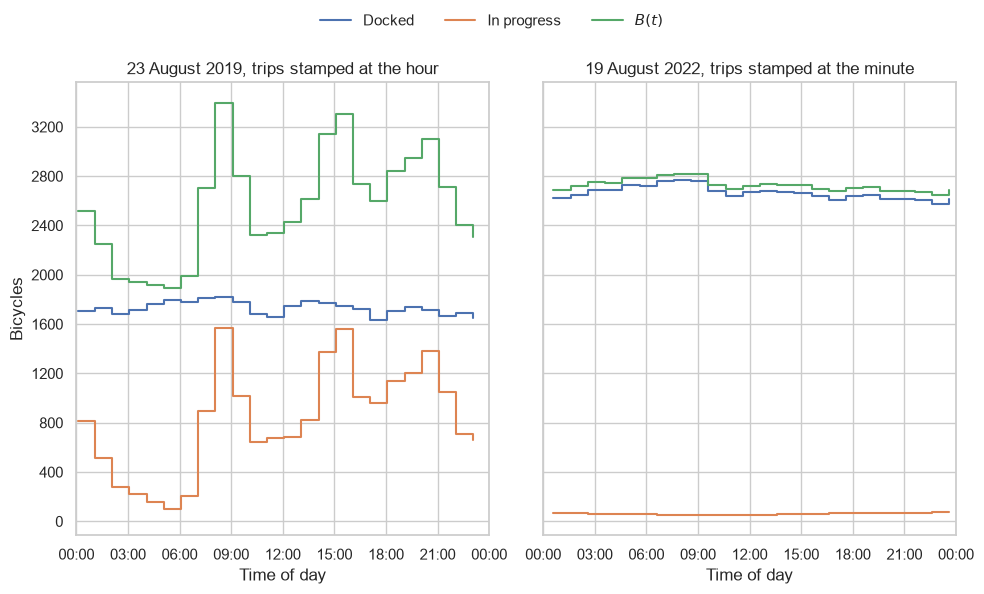

2019-08-23 Friday: 24 snapshots
  docked min 1,636 at 17:04, max 1,821 at 08:04
  riding min 98 at 05:04, max 1,572 at 08:04
  bikes min 1,892 at 05:04, max 3,393 at 08:04
2022-08-19 Friday: 24 snapshots
  docked min 2,574 at 22:36, max 2,767 at 07:36
  riding min 54 at 07:36, max 77 at 22:36
  bikes min 2,651 at 22:36, max 2,821 at 07:36
before 2021-06-01: 1066 days, bikes span median 294.5 p90 833, docked span median 263 p90 401
from 2021-06-01: 580 days, bikes span median 75 p90 135.3, docked span median 242 p90 371


In [2]:
import json

import matplotlib.dates as mdates

months = discover_months(cfg)["both"]
if not months:
    raise RuntimeError("No month has both a status file and a trip file.")
status_files = discover_status_files(cfg)
trip_files = discover_trip_files(cfg)
cache_dir = cfg.processed_dir / "infrastructure" / "bicycle_snapshots"

frames = []
for month in months:
    status_path = status_files[month]
    trip_path = trip_files[month]
    cache = cache_dir / f"{month}.parquet"
    manifest_path = cache_dir / f"{month}.manifest.json"
    manifest = {
        "status": {"file": status_path.name, "bytes": status_path.stat().st_size},
        "trips": {"file": trip_path.name, "bytes": trip_path.stat().st_size},
    }
    if not cache.is_file() or not manifest_path.is_file():
        raise RuntimeError(
            f"{month}: bicycle snapshot cache is missing. Run the bicycle section first."
        )
    saved = json.loads(manifest_path.read_text(encoding="utf-8"))
    if saved != manifest:
        raise RuntimeError(
            f"{month}: bicycle snapshot cache is stale. Run the bicycle section first."
        )
    frames.append(
        pd.read_parquet(cache, columns=["ts", "n_docked", "n_riding", "n_bikes"])
    )

snapshots = pd.concat(frames, ignore_index=True)
local = snapshots["ts"].dt.tz_convert(MADRID_TZ)
snapshots = snapshots.assign(local=local, day=local.dt.floor("D"))

examples = [
    ("2019-08-23", "23 August 2019, trips stamped at the hour"),
    ("2022-08-19", "19 August 2022, trips stamped at the minute"),
]
series = [
    ("n_docked", "Docked"),
    ("n_riding", "In progress"),
    ("n_bikes", r"$B(t)$"),
]

fig, axes = plt.subplots(1, 2, figsize=(10, 6), sharey=True)
for ax, (day, title) in zip(axes, examples):
    stamp = pd.Timestamp(day, tz=MADRID_TZ)
    day_frame = snapshots.loc[snapshots["day"].eq(stamp)].sort_values("local")
    if day_frame.empty:
        raise RuntimeError(f"{day} has no bicycle snapshots.")
    x = day_frame["local"].dt.tz_localize(None)
    for column, label in series:
        ax.step(x, day_frame[column], where="post", label=label)
    ax.set_title(title)
    ax.set_xlabel("Time of day")
    ax.set_xlim(pd.Timestamp(day), pd.Timestamp(day) + pd.Timedelta(days=1))
    ax.xaxis.set_major_locator(mdates.HourLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].set_ylabel("Bicycles")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()


def _num(value):
    number = float(value)
    if number.is_integer():
        return f"{int(number):,}"
    return f"{number:,.1f}"


def _at(frame, column, which):
    idx = frame[column].idxmin() if which == "min" else frame[column].idxmax()
    row = frame.loc[idx]
    return _num(row[column]), row["local"].strftime("%H:%M")


for day, _title in examples:
    stamp = pd.Timestamp(day, tz=MADRID_TZ)
    day_frame = snapshots.loc[snapshots["day"].eq(stamp)].sort_values("local")
    weekday = day_frame["local"].iloc[0].day_name()
    print(f"{day} {weekday}: {len(day_frame)} snapshots")
    for column, label in (("n_docked", "docked"), ("n_riding", "riding"), ("n_bikes", "bikes")):
        low, low_at = _at(day_frame, column, "min")
        high, high_at = _at(day_frame, column, "max")
        print(f"  {label} min {low} at {low_at}, max {high} at {high_at}")

grouped = snapshots.groupby("day", sort=True)
bikes_span = grouped["n_bikes"].max() - grouped["n_bikes"].min()
docked_span = grouped["n_docked"].max() - grouped["n_docked"].min()
cut = pd.Timestamp("2021-06-01", tz=MADRID_TZ)
for name, mask in (("before 2021-06-01", bikes_span.index < cut), ("from 2021-06-01", bikes_span.index >= cut)):
    bikes = bikes_span.loc[mask]
    docked = docked_span.loc[mask]
    print(
        f"{name}: {len(bikes)} days, "
        f"bikes span median {_num(bikes.median())} p90 {_num(bikes.quantile(0.9))}, "
        f"docked span median {_num(docked.median())} p90 {_num(docked.quantile(0.9))}"
    )


On Friday 23 August 2019 the 24 snapshots run from 98 trips in progress at 05:04 to 1,572 at 08:04. That 08:04 snapshot still has 1,821 bicycles in the docks, the most of the day, and $B(t)$ is 3,393. The lowest $B(t)$ is 1,892 at 05:04. The docked count stays between 1,636 and 1,821. This Friday is also the highest day of time in use in section 2.

On Friday 19 August 2022 the 24 snapshots keep trips in progress between 54 at 07:36 and 77 at 22:36. $B(t)$ stays between 2,651 and 2,821. The docked count stays between 2,574 and 2,767, with those extremes at the same snapshots.

Before 1 June 2021, over 1,066 days, the within-day span of $B(t)$ has median 294.5 and a 90th percentile of 833. From that date, over 580 days, the median span is 75 and the 90th percentile is 135.3. The docked span has median 263 before 1 June 2021 and 242 from then on.


### Docked bicycles at the quiet hour

$B(t)$ adds the trips in progress to the docked bicycles. Through May 2021 a bicycle can sit in `dock_bikes` and already count as in progress, so the same bicycle is counted twice. The count below uses only the bicycles reported in the docks. The first chart measures trip starts by hour of day in Europe/Madrid. The least active hour is the one with the fewest starts. Each day's value is the docked count in the snapshot taken during that hour.

Let $h^{*}$ be that hour. For a time $t$ on calendar day $D$,

$$
B(t) = \operatorname{median}\Bigl\{\sum_s d_s(u) : u \text{ is a snapshot on } D \text{ in hour } h^{*}\Bigr\}.
$$

$d_s(u)$ is `dock_bikes` at station $s$. The median is over the snapshots in that hour. $B(t)$ is the same at every moment of day $D$. A day with no snapshot in hour $h^{*}$ has no value.


2018-07: reading 201807_Usage_Bicimad.json


2018-07: 382,929 trips


2018-08: reading 201808_Usage_Bicimad.json


2018-08: 274,121 trips


2018-09: reading 201809_Usage_Bicimad.json


2018-09: 436,681 trips


... (98 outputs left out)

2022-11: reading trips_22_11_November.csv


2022-11: 358,393 trips


2022-12: reading trips_22_12_December.csv


2022-12: 246,564 trips


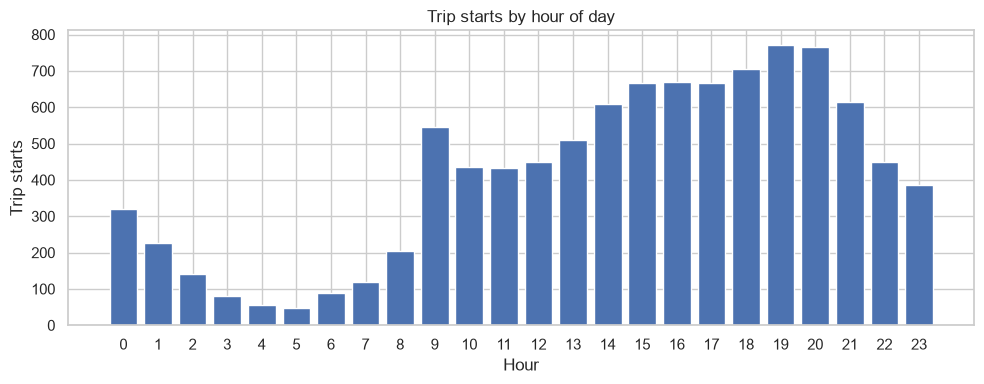

hour 00: median 319, mean 319.5
hour 01: median 226, mean 250.0
hour 02: median 142, mean 197.4
hour 03: median 80, mean 127.3
hour 04: median 56, mean 88.6
hour 05: median 47, mean 69.7
hour 06: median 88, mean 89.1
hour 07: median 120, mean 224.3
hour 08: median 203.5, mean 464.4
hour 09: median 544.5, mean 539.8
hour 10: median 436.5, mean 488.3
hour 11: median 432, mean 454.5
hour 12: median 448, mean 434.9
hour 13: median 511, mean 495.6
hour 14: median 609, mean 624.1
hour 15: median 665.5, mean 650.5
hour 16: median 668, mean 647.4
hour 17: median 666.5, mean 646.4
hour 18: median 706, mean 717.0
hour 19: median 772.5, mean 761.7
hour 20: median 764.5, mean 776.1
hour 21: median 615, mean 656.8
hour 22: median 448, mean 513.0
hour 23: median 385, mean 417.9
least active hour: 05


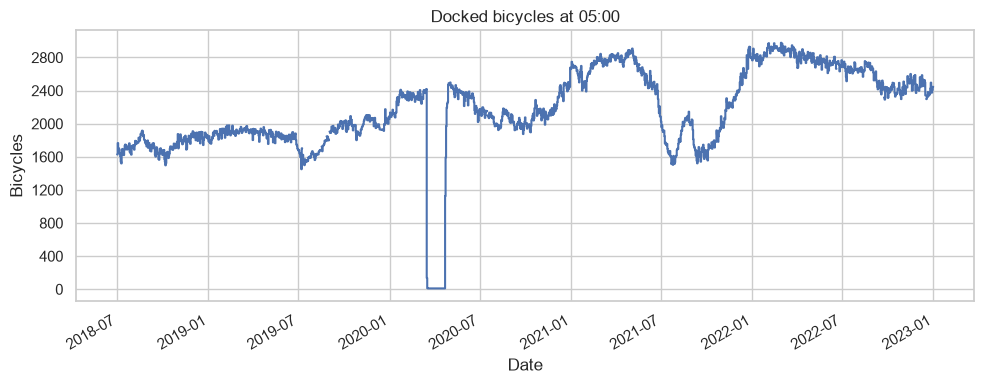

plotted days: 1,631
gap days: 2018-08-03, 2019-06-14, 2019-07-09, 2019-08-15, 2019-08-16, 2019-08-26, 2019-09-01, 2019-11-14, 2020-07-16, 2021-05-19, 2022-06-20, 2022-09-23, 2022-10-12, 2022-12-17, 2023-01-01
first day 2018-07-01: 1628.0
last day 2022-12-31: 2446.0
minimum 10.0 on 2020-03-18
maximum 2978.0 on 2022-02-28


In [2]:
import json
import re

import numpy as np

months = discover_months(cfg)["both"]
if not months:
    raise RuntimeError("No month has both a status file and a trip file.")
status_files = discover_status_files(cfg)
trip_files = discover_trip_files(cfg)
cache_dir = cfg.processed_dir / "infrastructure" / "bicycle_snapshots"

origin = pd.Timestamp("2018-07-01", tz=MADRID_TZ)
horizon = pd.Timestamp("2023-01-02", tz=MADRID_TZ)
n_days = int((horizon - origin) / pd.Timedelta(days=1))
starts_by_hour = np.zeros((n_days, 24), dtype=np.int32)

unplug_re = re.compile(
    r'"unplug_hourTime"\s*:\s*(?:\{\s*"\$date"\s*:\s*)?"([^"]+)"'
)
travel_re = re.compile(r'"travel_time"\s*:\s*(-?\d+(?:\.\d+)?(?:[eE][+-]?\d+)?)')
batch = []


def _add_local(local):
    if len(local) == 0:
        return
    rows = np.asarray((local.dt.floor("D") - origin) / pd.Timedelta(days=1), dtype=int)
    hours = local.dt.hour.to_numpy()
    if rows.min() < 0 or rows.max() >= n_days:
        raise RuntimeError("A trip start falls outside July 2018 through 1 January 2023.")
    np.add.at(starts_by_hour, (rows, hours), 1)


def _flush_batch():
    if not batch:
        return
    normalized = pd.Series(batch).str.replace(
        r"([+-]\d{2})(\d{2})$", r"\1:\2", regex=True
    )
    parsed = pd.to_datetime(normalized, utc=True, errors="coerce").dropna()
    _add_local(parsed.dt.tz_convert(MADRID_TZ))
    batch.clear()


for month in months:
    path = trip_files[month]
    if not path.is_file():
        raise RuntimeError(f"{month}: trip file {path.name} is not on disk.")
    print(f"{month}: reading {path.name}", flush=True)
    if path.suffix.lower() == ".json":
        kept = 0
        with path.open("r", encoding="utf-8", errors="replace") as handle:
            for line in handle:
                stamp = unplug_re.search(line)
                if stamp is None:
                    continue
                duration = travel_re.search(line)
                if duration is None or not float(duration.group(1)) > 0:
                    continue
                batch.append(stamp.group(1))
                kept += 1
                if len(batch) >= 250_000:
                    _flush_batch()
        _flush_batch()
        print(f"{month}: {kept:,} trips", flush=True)
        continue
    with path.open("r", encoding="utf-8", errors="replace") as handle:
        header = handle.readline()
    if "unlock_date" in header and "lock_date" in header:
        frame = pd.read_csv(
            path,
            sep=";",
            usecols=["unlock_date", "lock_date"],
            dtype=str,
            encoding="utf-8",
            encoding_errors="replace",
            low_memory=False,
        )
        start = pd.to_datetime(frame["unlock_date"], utc=True, errors="coerce")
        end = pd.to_datetime(frame["lock_date"], utc=True, errors="coerce")
        ok = start.notna() & end.notna() & end.gt(start)
        _add_local(start.loc[ok].dt.tz_convert(MADRID_TZ))
        print(f"{month}: {int(ok.sum()):,} trips", flush=True)
        continue
    start_int, _end_int = trip_intervals(path)
    unit = "ns" if int(start_int[0]) > 10**17 else "us"
    local = pd.to_datetime(start_int, unit=unit, utc=True).tz_convert(MADRID_TZ)
    _add_local(pd.Series(local))
    print(f"{month}: {len(start_int):,} trips", flush=True)

frames = []
for month in months:
    status_path = status_files[month]
    trip_path = trip_files[month]
    cache = cache_dir / f"{month}.parquet"
    manifest_path = cache_dir / f"{month}.manifest.json"
    manifest = {
        "status": {"file": status_path.name, "bytes": status_path.stat().st_size},
        "trips": {"file": trip_path.name, "bytes": trip_path.stat().st_size},
    }
    if not cache.is_file() or not manifest_path.is_file():
        raise RuntimeError(
            f"{month}: bicycle snapshot cache is missing. Run the bicycle section first."
        )
    saved = json.loads(manifest_path.read_text(encoding="utf-8"))
    if saved != manifest:
        raise RuntimeError(
            f"{month}: bicycle snapshot cache is stale. Run the bicycle section first."
        )
    frames.append(pd.read_parquet(cache, columns=["ts", "n_docked"]))

snapshots = pd.concat(frames, ignore_index=True)
local_ts = snapshots["ts"].dt.tz_convert(MADRID_TZ)
calendar = pd.date_range(local_ts.dt.floor("D").min(), local_ts.dt.floor("D").max(), freq="D", tz=MADRID_TZ)
cal_rows = np.asarray((calendar - origin) / pd.Timedelta(days=1), dtype=int)
if cal_rows.min() < 0 or cal_rows.max() >= n_days:
    raise RuntimeError("Snapshot days fall outside the trip-start grid.")
block = starts_by_hour[cal_rows]
medians = np.median(block, axis=0)
means = block.mean(axis=0)
quiet = min(range(24), key=lambda hour: (medians[hour], means[hour], hour))

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(np.arange(24), medians)
ax.set_xticks(range(24))
ax.set_title("Trip starts by hour of day")
ax.set_xlabel("Hour")
ax.set_ylabel("Trip starts")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()
plt.show()


def _num(value):
    number = float(value)
    if number.is_integer():
        return f"{int(number):,}"
    return f"{number:,.1f}"


for hour in range(24):
    print(f"hour {hour:02d}: median {_num(medians[hour])}, mean {_num(means[hour])}")
print(f"least active hour: {quiet:02d}")

quiet_mask = local_ts.dt.hour.eq(quiet)
chosen = snapshots.loc[quiet_mask]
chosen_day = local_ts.loc[quiet_mask].dt.floor("D")
daily = chosen.groupby(chosen_day)["n_docked"].median()


def _as_count(series: pd.Series) -> pd.Series:
    values = pd.to_numeric(series, errors="coerce")
    if values.dropna().empty or values.dropna().mod(1).eq(0).all():
        return values.round().astype("Int64")
    return values


daily = _as_count(daily)
quiet_plot = daily.reindex(calendar)

fig, ax = plt.subplots(figsize=(10, 4))
ax.step(quiet_plot.index.tz_localize(None), quiet_plot, where="post")
ax.set_title(f"Docked bicycles at {quiet:02d}:00")
ax.set_xlabel("Date")
ax.set_ylabel("Bicycles")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

present = quiet_plot.dropna()
gaps = [ts.strftime("%Y-%m-%d") for ts in quiet_plot.index[quiet_plot.isna()]]
print(f"plotted days: {len(present):,}")
print("gap days:", ", ".join(gaps) if gaps else "none")
print(f"first day {present.index[0].strftime('%Y-%m-%d')}: {present.iloc[0]}")
print(f"last day {present.index[-1].strftime('%Y-%m-%d')}: {present.iloc[-1]}")
print(f"minimum {present.min()} on {present.idxmin().strftime('%Y-%m-%d')}")
print(f"maximum {present.max()} on {present.idxmax().strftime('%Y-%m-%d')}")


The fewest trip starts fall in hour 05. On the days with a station snapshot, the median number of starts in that hour is 47. Hour 04 has a median of 56 and hour 06 has a median of 88. The median then rises through the morning. The highest median is 772.5 starts at 19:00, and hour 20 has 764.5.

The docked series uses that hour on every day. It is the $B(t)$ defined above. The line has 1,631 days. It starts at 1,628 on 1 July 2018 and ends at 2,446 on 31 December 2022. The minimum is 10, first reached on 18 March 2020, when the closure left the docked fleet at that level. The maximum is 2,978 on 28 February 2022. Fifteen days have no snapshot in hour 05: 3 August 2018, 14 June 2019, 9 July 2019, 15 August 2019, 16 August 2019, 26 August 2019, 1 September 2019, 14 November 2019, 16 July 2020, 19 May 2021, 20 June 2022, 23 September 2022, 12 October 2022, 17 December 2022, and 1 January 2023.


## 2. Time in use over time

The total time bicycles spend in use on a calendar day $D$ in Europe/Madrid is the numerator of the utilization rate.

$$
T(D) = \int_D R(t)\,dt.
$$

$R(t)$ is the number of trips in progress from section 1. The integral is in bicycle-hours. One bicycle in use for one hour contributes one. Between two consecutive snapshots the count is held at the earlier snapshot. An interval that crosses midnight is split between the two days. A gap longer than 6 hours is left out of the integral. A day with less than 12 hours of that bracketed time, or whose quiet-hour fleet is missing or zero, is a gap in the line.

The plotted value is $T(D)$ on each calendar day. The code reads the snapshot caches written by the bicycle section and uses the quiet-hour $B(t)$ for that presence test.


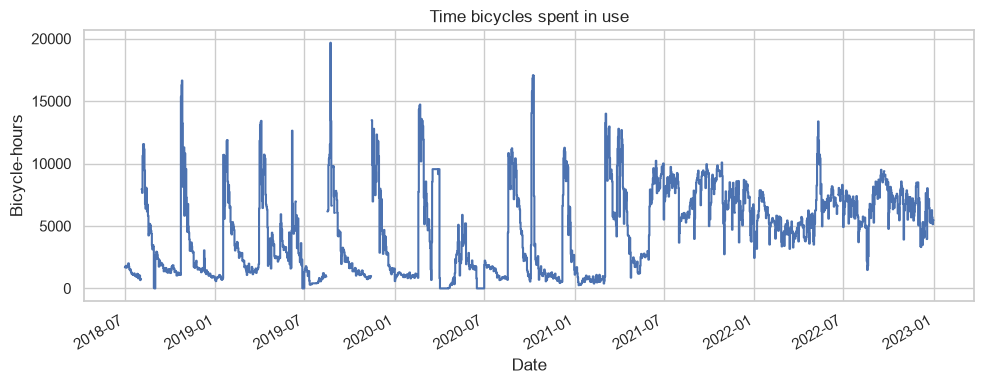

months used: 54 (2018-07 to 2022-12)
months inside that span without both files: none
plotted days: 1,630
gap days: 2018-08-03, 2019-06-14, 2019-07-09, 2019-08-15, 2019-08-16, 2019-08-26, 2019-09-01, 2019-11-14, 2020-07-16, 2021-05-19, 2021-11-23, 2022-06-20, 2022-09-23, 2022-10-12, 2022-12-17, 2023-01-01
first day 2018-07-01: 1688.0
last day 2022-12-31: 5471.0
minimum 0.0 on 2018-08-30
maximum 19675.1 on 2019-08-23
median 4221.1
year 2018: median 1639.6 over 183 days
year 2019: median 2421.8 over 358 days
year 2020: median 1507.6 over 365 days
year 2021: median 6741.9 over 363 days
year 2022: median 6216.9 over 361 days
2020-03-17 to 2020-03-31: 15 days, min 8539.7, max 9552.0
2020-04-01 to 2020-04-01: 1 day, min 809.0, max 809.0
2020-04-02 to 2020-04-18: 17 days, min 0.0, max 0.0


In [2]:
import json

QUIET_HOUR = 5  # hour h* from the quiet-hour chart

months = discover_months(cfg)["both"]
if not months:
    raise RuntimeError("No month has both a status file and a trip file.")
status_files = discover_status_files(cfg)
trip_files = discover_trip_files(cfg)
cache_dir = cfg.processed_dir / "infrastructure" / "bicycle_snapshots"

frames = []
for month in months:
    status_path = status_files[month]
    trip_path = trip_files[month]
    cache = cache_dir / f"{month}.parquet"
    manifest_path = cache_dir / f"{month}.manifest.json"
    manifest = {
        "status": {"file": status_path.name, "bytes": status_path.stat().st_size},
        "trips": {"file": trip_path.name, "bytes": trip_path.stat().st_size},
    }
    if not cache.is_file() or not manifest_path.is_file():
        raise RuntimeError(
            f"{month}: bicycle snapshot cache is missing. Run the bicycle section first."
        )
    saved = json.loads(manifest_path.read_text(encoding="utf-8"))
    if saved != manifest:
        raise RuntimeError(
            f"{month}: bicycle snapshot cache is stale. Run the bicycle section first."
        )
    frames.append(pd.read_parquet(cache, columns=["ts", "n_riding", "n_docked"]))

snapshots = pd.concat(frames, ignore_index=True)
local = snapshots["ts"].dt.tz_convert(MADRID_TZ)
snapshots["date"] = local.dt.floor("D")
quiet = snapshots.loc[local.dt.hour.eq(QUIET_HOUR)]
daily_b = quiet.groupby("date")["n_docked"].median()
snapshots["n_bikes"] = snapshots["date"].map(daily_b)
daily = daily_presence_utilization(
    snapshots,
    tz=MADRID_TZ,
    max_gap=pd.Timedelta(hours=6),
)
calendar = pd.date_range(
    snapshots["date"].min(), snapshots["date"].max(), freq="D", tz=MADRID_TZ
)
plot = daily.set_index("date").reindex(calendar)
fleet = daily_b.reindex(calendar)
eligible = plot["covered_hours"].ge(12) & fleet.gt(0)
used = plot["used_hours"].where(eligible)

fig, ax = plt.subplots()
ax.step(used.index.tz_localize(None), used, where="post")
ax.set_title("Time bicycles spent in use")
ax.set_xlabel("Date")
ax.set_ylabel("Bicycle-hours")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

present = used.dropna()
gaps = [ts.strftime("%Y-%m-%d") for ts in used.index[used.isna()]]
span = pd.period_range(months[0], months[-1], freq="M")
inside_missing = [str(period) for period in span if str(period) not in set(months)]
print(f"months used: {len(months)} ({months[0]} to {months[-1]})")
print("months inside that span without both files:", inside_missing or "none")
print(f"plotted days: {len(present):,}")
print("gap days:", ", ".join(gaps) if gaps else "none")
print(f"first day {present.index[0].strftime('%Y-%m-%d')}: {present.iloc[0]:.1f}")
print(f"last day {present.index[-1].strftime('%Y-%m-%d')}: {present.iloc[-1]:.1f}")
print(f"minimum {present.min():.1f} on {present.idxmin().strftime('%Y-%m-%d')}")
print(f"maximum {present.max():.1f} on {present.idxmax().strftime('%Y-%m-%d')}")
print(f"median {present.median():.1f}")
for year, group in present.groupby(present.index.year):
    print(f"year {year}: median {group.median():.1f} over {len(group)} days")


def _window(start, end):
    sl = present.loc[start:end]
    noun = "day" if len(sl) == 1 else "days"
    print(
        f"{start} to {end}: {len(sl)} {noun}, "
        f"min {sl.min():.1f}, max {sl.max():.1f}"
    )


_window("2020-03-17", "2020-03-31")
_window("2020-04-01", "2020-04-01")
_window("2020-04-02", "2020-04-18")


The daily value of $T(D)$ starts at 1,688 bicycle-hours on 1 July 2018 and the last plotted day is 5,471 on 31 December 2022. The median of the plotted days is 4,221.1. The highest day is 19,675.1 on 23 August 2019. The median within each year is 1,639.6 in 2018, 2,421.8 in 2019, 1,507.6 in 2020, 6,741.9 in 2021, and 6,216.9 in 2022.

From 17 March through 31 March 2020 the total stays between 8,539.7 and 9,552 bicycle-hours. Trips left open in the March file keep counting as time in use. On 1 April the total is 809, because the last March snapshot is held across midnight. From 2 April through 18 April the total is 0.

The minimum is 0, first reached on 30 August 2018. Those zero days are the same absences in the published trip files described in section 7, while the quiet-hour fleet is still present. Sixteen days are gaps. Fifteen have no snapshot in hour 05: 3 August 2018, 14 June 2019, 9 July 2019, 15 August 2019, 16 August 2019, 26 August 2019, 1 September 2019, 14 November 2019, 16 July 2020, 19 May 2021, 20 June 2022, 23 September 2022, 12 October 2022, 17 December 2022, and 1 January 2023. On 23 November 2021 the quiet-hour fleet is present, and the day is a gap because less than 12 hours of snapshots are bracketed. The series uses the same 54 months as the bicycle count, July 2018 through December 2022.


## 3. Docks in the network over time

The number of docks at snapshot time $t$ is

$$
C(t) = \sum_s c_s(t).
$$

$c_s(t)$ is `total_bases` at station $s$. The sum covers every listed station, including a station with `no_available` equal to 1. A missing `total_bases` counts as zero.

The plotted value is the median of $C(t)$ on each calendar day in Europe/Madrid. A day with no snapshot is a gap in the line. The code reads the dock totals cached from the status files for July 2018 through December 2022.


2018-07: cached, 744 snapshots


2018-08: cached, 755 snapshots


2018-09: cached, 719 snapshots

2018-10: cached, 745 snapshots


2018-11: cached, 726 snapshots


2018-12: cached, 736 snapshots


... (44 outputs left out)

2022-09: cached, 717 snapshots


2022-10: cached, 739 snapshots


2022-11: cached, 717 snapshots


2022-12: cached, 725 snapshots


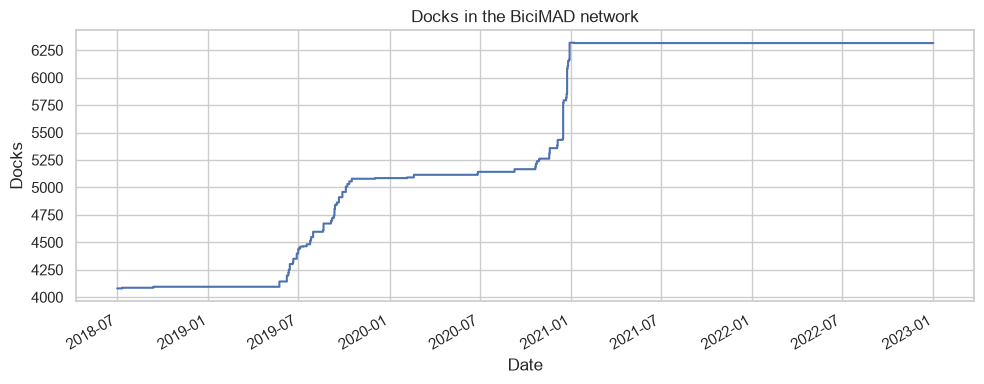

months used: 54 (2018-07 to 2022-12)
months inside that span without a status file: none
snapshots: 39,252
snapshots with no docks: 0
gap days: 0
first day 2018-07-01: 4080.0
last day 2023-01-01: 6315.0
minimum 4080.0 on 2018-07-01
maximum 6318.0 on 2020-12-29


In [2]:
import json

status_files = discover_status_files(cfg)
months = list(status_files)
if not months:
    raise RuntimeError("No status files are on disk.")
dock_dir = cfg.processed_dir / "infrastructure" / "dock_counts"
dock_dir.mkdir(parents=True, exist_ok=True)

frames = []
for month in months:
    status_path = status_files[month]
    dock_cache = dock_dir / f"{month}.parquet"
    dock_manifest_path = dock_dir / f"{month}.manifest.json"
    manifest = {"status": {"file": status_path.name, "bytes": status_path.stat().st_size}}
    docks = None
    if dock_cache.is_file() and dock_manifest_path.is_file():
        saved = json.loads(dock_manifest_path.read_text(encoding="utf-8"))
        if saved == manifest:
            docks = pd.read_parquet(dock_cache)
            print(f"{month}: cached, {len(docks):,} snapshots", flush=True)
    if docks is None:
        print(f"{month}: counting docks in {status_path.name}", flush=True)
        docks = snapshot_dock_capacity(status_path)
        docks.to_parquet(dock_cache, index=False)
        dock_manifest_path.write_text(json.dumps(manifest), encoding="utf-8")
        print(f"{month}: {len(docks):,} snapshots", flush=True)
    frames.append(docks.loc[:, ["ts", "n_docks"]])

snapshots = pd.concat(frames, ignore_index=True)
local_day = snapshots["ts"].dt.tz_convert(MADRID_TZ).dt.floor("D")
daily = (
    snapshots.assign(date=local_day)
    .groupby("date", as_index=False)
    .agg(n_docks=("n_docks", "median"))
    .sort_values("date")
    .reset_index(drop=True)
)


def _as_count(series: pd.Series) -> pd.Series:
    values = pd.to_numeric(series, errors="coerce")
    if values.dropna().empty or values.dropna().mod(1).eq(0).all():
        return values.round().astype("Int64")
    return values


daily["n_docks"] = _as_count(daily["n_docks"])
span_start = snapshots["ts"].dt.tz_convert(MADRID_TZ).dt.floor("D").min()
span_end = snapshots["ts"].dt.tz_convert(MADRID_TZ).dt.floor("D").max()
calendar = pd.date_range(span_start, span_end, freq="D", tz=MADRID_TZ)
plot = daily.set_index("date").reindex(calendar)

fig, ax = plt.subplots()
ax.step(plot.index.tz_localize(None), plot["n_docks"], where="post")
ax.set_title("Docks in the BiciMAD network")
ax.set_xlabel("Date")
ax.set_ylabel("Docks")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

present = plot["n_docks"].dropna()
period_span = pd.period_range(months[0], months[-1], freq="M")
inside_missing = [str(period) for period in period_span if str(period) not in set(months)]
print(f"months used: {len(months)} ({months[0]} to {months[-1]})")
print("months inside that span without a status file:", inside_missing or "none")
print(f"snapshots: {len(snapshots):,}")
print(f"snapshots with no docks: {int((snapshots['n_docks'] == 0).sum()):,}")
print(f"gap days: {int(plot['n_docks'].isna().sum())}")
print(f"first day {present.index[0].strftime('%Y-%m-%d')}: {present.iloc[0]}")
print(f"last day {present.index[-1].strftime('%Y-%m-%d')}: {present.iloc[-1]}")
print(f"minimum {present.min()} on {present.idxmin().strftime('%Y-%m-%d')}")
print(f"maximum {present.max()} on {present.idxmax().strftime('%Y-%m-%d')}")


In [3]:
changed = daily["n_docks"].diff().fillna(0).ne(0)
changed.iloc[0] = True
changes = daily.loc[changed, ["date", "n_docks"]].copy()
changes["change"] = changes["n_docks"].diff()
changes["date"] = changes["date"].dt.strftime("%Y-%m-%d")
changes = changes.rename(columns={"n_docks": "docks"})
with pd.option_context("display.max_rows", None):
    display(changes)


,date,docks,change
0,2018-07-01,4080.0,NaN
10,2018-07-11,4086.0,6.0
73,2018-09-12,4095.0,9.0
327,2019-05-24,4143.0,48.0
342,2019-06-08,4197.0,54.0
345,2019-06-11,4224.0,27.0
346,2019-06-12,4251.0,27.0
348,2019-06-14,4302.0,51.0
354,2019-06-20,4315.5,13.5
355,2019-06-21,4350.0,34.5


The daily median of $C(t)$ starts at 4,080 docks on 1 July 2018 and ends at 6,315 on 1 January 2023. The highest day is 6,318 on 29 December 2020. From 8 January 2021 through 1 January 2023 the median stays at 6,315.

The median steps down twice. On 4 July 2019 it falls from 4,446 to 4,443. On 8 January 2021 it falls from 6,318 to 6,315. On 20 June 2019 the median is 4,315.5. A half dock is a day whose hourly snapshots were split between two counts, so the median lies halfway between them. The table lists every day the median changes.

The series uses the status files from July 2018 through December 2022, the same 54 months as the bicycle count. All 39,252 snapshots have a dock total. No calendar day from 1 July 2018 through 1 January 2023 is missing a snapshot. The point on 1 January 2023 is the single snapshot at the end of the December 2022 status file.


## 4. Bicycles per dock over time

The density of the network is the quiet-hour fleet divided by the dock count.

$$
\delta(t) = \frac{B(t)}{C(t)}.
$$

$B(t)$ is the quiet-hour fleet from section 1, constant through the day. $C(t)$ is the daily median dock count plotted in section 3. A day missing either value is a gap in the line.

The plotted value is $\delta(t)$ on each calendar day in Europe/Madrid. The code reads the bicycle snapshot caches and the dock-count cache.


2018-07: cached, 744 snapshots


2018-08: cached, 755 snapshots


2018-09: cached, 719 snapshots


2018-10: cached, 745 snapshots

2018-11: cached, 726 snapshots

2018-12: cached, 736 snapshots

... (44 outputs left out)

2022-09: cached, 717 snapshots


2022-10: cached, 739 snapshots


2022-11: cached, 717 snapshots


2022-12: cached, 725 snapshots


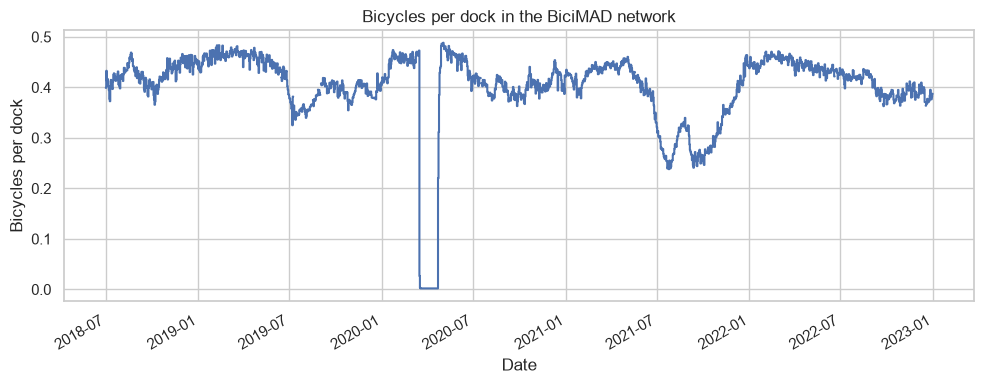

months used: 54 (2018-07 to 2022-12)
months inside that span without both files: none
snapshots: 39,252
snapshots with no docks: 0
plotted days: 1,631
gap days: 2018-08-03, 2019-06-14, 2019-07-09, 2019-08-15, 2019-08-16, 2019-08-26, 2019-09-01, 2019-11-14, 2020-07-16, 2021-05-19, 2022-06-20, 2022-09-23, 2022-10-12, 2022-12-17, 2023-01-01
first day 2018-07-01: 0.399
last day 2022-12-31: 0.387
minimum 0.002 on 2020-03-18
maximum 0.488 on 2020-05-02
year 2018: median 0.428 over 183 days
year 2019: median 0.414 over 358 days
year 2020: median 0.415 over 365 days
year 2021: median 0.390 over 364 days
year 2022: median 0.428 over 361 days
2020-03-18 to 2020-03-31: 14 days, min 0.002, max 0.002
2020-04-01 to 2020-04-18: 18 days, min 0.002, max 0.002


In [3]:
import json

QUIET_HOUR = 5  # hour h* from the quiet-hour chart

months = discover_months(cfg)["both"]
if not months:
    raise RuntimeError("No month has both a status file and a trip file.")
status_files = discover_status_files(cfg)
bike_dir = cfg.processed_dir / "infrastructure" / "bicycle_snapshots"
dock_dir = cfg.processed_dir / "infrastructure" / "dock_counts"
dock_dir.mkdir(parents=True, exist_ok=True)

frames = []
for month in months:
    status_path = status_files[month]
    bike_cache = bike_dir / f"{month}.parquet"
    bike_manifest_path = bike_dir / f"{month}.manifest.json"
    if not bike_cache.is_file() or not bike_manifest_path.is_file():
        raise RuntimeError(
            f"{month}: bicycle snapshot cache is missing. Run the bicycle section first."
        )
    saved_bikes = json.loads(bike_manifest_path.read_text(encoding="utf-8"))
    status_manifest = {"file": status_path.name, "bytes": status_path.stat().st_size}
    if saved_bikes.get("status") != status_manifest:
        raise RuntimeError(
            f"{month}: bicycle snapshot cache is stale. Run the bicycle section first."
        )
    bikes = pd.read_parquet(bike_cache, columns=["ts", "n_docked"])

    dock_cache = dock_dir / f"{month}.parquet"
    dock_manifest_path = dock_dir / f"{month}.manifest.json"
    manifest = {"status": status_manifest}
    docks = None
    if dock_cache.is_file() and dock_manifest_path.is_file():
        saved = json.loads(dock_manifest_path.read_text(encoding="utf-8"))
        if saved == manifest:
            docks = pd.read_parquet(dock_cache)
            print(f"{month}: cached, {len(docks):,} snapshots", flush=True)
    if docks is None:
        print(f"{month}: counting docks in {status_path.name}", flush=True)
        docks = snapshot_dock_capacity(status_path)
        docks.to_parquet(dock_cache, index=False)
        dock_manifest_path.write_text(json.dumps(manifest), encoding="utf-8")
        print(f"{month}: {len(docks):,} snapshots", flush=True)

    merged = bikes.merge(docks, on="ts", how="outer", indicator=True)
    missing = int((merged["_merge"] != "both").sum())
    if missing:
        raise RuntimeError(
            f"{month}: {missing} snapshots are missing from the bicycle cache or the dock count"
        )
    frames.append(merged.loc[:, ["ts", "n_docked", "n_docks"]])

snapshots = pd.concat(frames, ignore_index=True)
local = snapshots["ts"].dt.tz_convert(MADRID_TZ)
snapshots["date"] = local.dt.floor("D")
quiet = snapshots.loc[local.dt.hour.eq(QUIET_HOUR)]
daily_b = quiet.groupby("date")["n_docked"].median()
daily_c = snapshots.groupby("date")["n_docks"].median()
calendar = pd.date_range(
    snapshots["date"].min(), snapshots["date"].max(), freq="D", tz=MADRID_TZ
)
plot = pd.DataFrame({"B": daily_b, "C": daily_c}).reindex(calendar)
plot["density"] = plot["B"] / plot["C"]
missing_day = plot["B"].isna() | plot["C"].isna() | plot["C"].le(0)
plot.loc[missing_day, "density"] = pd.NA

fig, ax = plt.subplots()
ax.step(plot.index.tz_localize(None), plot["density"], where="post")
ax.set_title("Bicycles per dock in the BiciMAD network")
ax.set_xlabel("Date")
ax.set_ylabel("Bicycles per dock")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

present = plot["density"].dropna()
gaps = [ts.strftime("%Y-%m-%d") for ts in plot.index[plot["density"].isna()]]
period_span = pd.period_range(months[0], months[-1], freq="M")
inside_missing = [str(period) for period in period_span if str(period) not in set(months)]
print(f"months used: {len(months)} ({months[0]} to {months[-1]})")
print("months inside that span without both files:", inside_missing or "none")
print(f"snapshots: {len(snapshots):,}")
print(f"snapshots with no docks: {int((snapshots['n_docks'] == 0).sum()):,}")
print(f"plotted days: {len(present):,}")
print("gap days:", ", ".join(gaps) if gaps else "none")
print(f"first day {present.index[0].strftime('%Y-%m-%d')}: {present.iloc[0]:.3f}")
print(f"last day {present.index[-1].strftime('%Y-%m-%d')}: {present.iloc[-1]:.3f}")
print(f"minimum {present.min():.3f} on {present.idxmin().strftime('%Y-%m-%d')}")
print(f"maximum {present.max():.3f} on {present.idxmax().strftime('%Y-%m-%d')}")
for year, group in present.groupby(present.index.year):
    print(f"year {year}: median {group.median():.3f} over {len(group)} days")


def _window(start, end):
    sl = present.loc[start:end]
    print(f"{start} to {end}: {len(sl)} days, min {sl.min():.3f}, max {sl.max():.3f}")


_window("2020-03-18", "2020-03-31")
_window("2020-04-01", "2020-04-18")


The daily value of $\delta(t)$ starts at 0.399 bicycles per dock on 1 July 2018 and ends at 0.387 on 31 December 2022. The highest day is 0.488 on 2 May 2020. The median within each year is 0.428 in 2018, 0.414 in 2019, 0.415 in 2020, 0.390 in 2021, and 0.428 in 2022.

From 18 March through 31 March 2020, and from 1 April through 18 April, the value is 0.002. The minimum is 0.002 on 18 March 2020, the day the quiet-hour fleet in section 1 first reaches 10. The docks stay listed through the closure.

The series uses the same 54 months as the bicycle count, July 2018 through December 2022. All 39,252 snapshots have a dock total. Fifteen days are gaps because they have no snapshot in hour 05: 3 August 2018, 14 June 2019, 9 July 2019, 15 August 2019, 16 August 2019, 26 August 2019, 1 September 2019, 14 November 2019, 16 July 2020, 19 May 2021, 20 June 2022, 23 September 2022, 12 October 2022, 17 December 2022, and 1 January 2023.


## 5. Stations in the network over time

The EMT historical package publishes a snapshot of every station about once an hour. At snapshot time $t$ the size of the network is

$$
N(t) = |\{\text{stations listed in the EMT status snapshot at } t\}|.
$$

A station is active when the snapshot field `activate` equals 1. EMT can keep listing a station that is out of service, so the two counts are kept separate.

The plotted series is the median of each count inside a calendar day in Europe/Madrid. A day with no snapshot is a gap in the line. The download below takes only the station-status members of the 2017–2023 archives. Trip files stay on the server. A file already in `data/raw/status` is left as it is, and the snapshot counts are cached under `data/processed/infrastructure`.


In [4]:
report = ensure_status_files(cfg)
counts = load_snapshot_station_counts(cfg)

months = sorted(counts["month"].unique())
span = pd.period_range(months[0], months[-1], freq="M")
missing = [str(period) for period in span if str(period) not in set(months)]
unpublished = (
    report.loc[report["action"].eq("not published"), "year"].astype(int).tolist()
)
print(f"snapshots: {len(counts):,}")
print(f"status months: {months[0]} to {months[-1]} ({len(months)} months)")
print("months missing inside that span:", missing or "none")
print("yearly archives with no status files:", unpublished)


EMT 2017: listing https://media.emtmadrid.es/-HoGTStPZeC


EMT 2017: archive has no station-status files.


EMT 2018: listing https://media.emtmadrid.es/-9iZNUjrjri


EMT 2019: listing https://media.emtmadrid.es/-WNgfSj2ZvC


EMT 2020: listing https://media.emtmadrid.es/-rkuBymuFJX


EMT 2021: listing https://media.emtmadrid.es/-BRk4rTaAdV


EMT 2022: listing https://media.emtmadrid.es/-uHaW6iZkhG


EMT 2023: listing https://media.emtmadrid.es/-9Nii5DXo4x


EMT 2023: archive has no station-status files.


snapshots: 39,252
status months: 2018-07 to 2022-12 (54 months)
months missing inside that span: none
yearly archives with no status files: [2017, 2023]


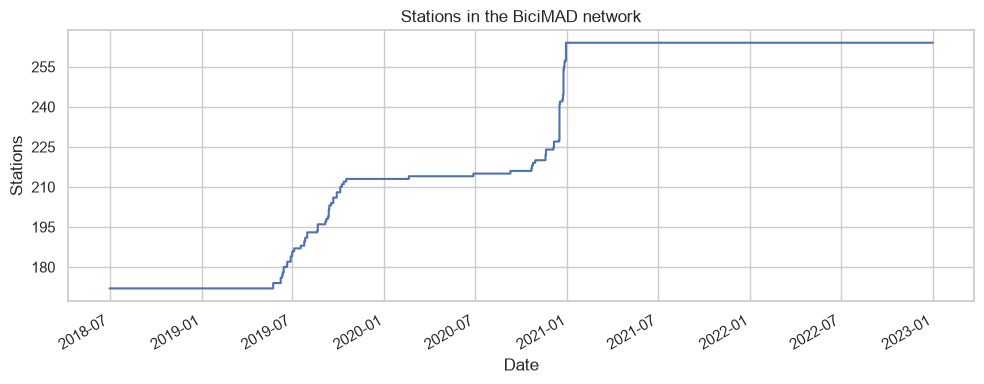

In [5]:
local_day = counts["ts"].dt.tz_convert(MADRID_TZ).dt.floor("D")
daily = (
    counts.assign(date=local_day)
    .groupby("date", as_index=False)
    .agg(n_stations=("n_stations", "median"), n_active=("n_active", "median"))
    .sort_values("date")
    .reset_index(drop=True)
)


def _as_count(series: pd.Series) -> pd.Series:
    values = pd.to_numeric(series, errors="coerce")
    if values.dropna().empty or values.dropna().mod(1).eq(0).all():
        return values.round().astype("Int64")
    return values


daily["n_stations"] = _as_count(daily["n_stations"])
daily["n_active"] = _as_count(daily["n_active"])

calendar = pd.date_range(daily["date"].min(), daily["date"].max(), freq="D", tz=MADRID_TZ)
plot = daily.set_index("date").reindex(calendar)
active_differs = bool(
    (
        plot["n_stations"].notna()
        & plot["n_active"].notna()
        & plot["n_stations"].ne(plot["n_active"])
    ).any()
)

fig, ax = plt.subplots()
x = plot.index.tz_localize(None)
ax.step(x, plot["n_stations"], where="post", label="Listed in the snapshot")
if active_differs:
    ax.step(x, plot["n_active"], where="post", label="Active (activate = 1)")
    ax.legend(frameon=False)
ax.set_title("Stations in the BiciMAD network")
ax.set_xlabel("Date")
ax.set_ylabel("Stations")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


In [6]:
listed_changed = daily["n_stations"].diff().fillna(0).ne(0)
active_changed = daily["n_active"].diff().fillna(0).ne(0)
presence_changed = daily["n_active"].isna().astype(int).diff().fillna(0).ne(0)
changed = listed_changed | active_changed | presence_changed
changed.iloc[0] = True

changes = daily.loc[changed, ["date", "n_stations", "n_active"]].copy()
changes["change"] = changes["n_stations"].diff()
changes["date"] = changes["date"].dt.strftime("%Y-%m-%d")
changes = changes.rename(columns={"n_stations": "listed", "n_active": "active"})
changes


,date,listed,active,change
0,2018-07-01,172.0,172.0,<NA>
327,2019-05-24,174.0,174.0,2.0
342,2019-06-08,176.0,176.0,2.0
345,2019-06-11,177.0,177.0,1.0
346,2019-06-12,178.0,178.0,1.0
348,2019-06-14,180.0,180.0,2.0
354,2019-06-20,180.5,180.5,0.5
355,2019-06-21,182.0,182.0,1.5
362,2019-06-28,184.0,184.0,2.0
365,2019-07-01,185.5,185.5,1.5


## 6. Reading the series

From 1 July 2018 through 1 January 2023 the daily median rises from 172 stations to 264. Every step in the table is an increase. On every snapshot the active count equals the listed count, so `activate` is 1 for every station in these files.

The median stays at 172 until 24 May 2019. It then rises through the rest of 2019 and reaches 213 on 17 October 2019. The next additions are 214 on 19 February 2020, 215 on 27 June 2020, and 216 on 9 September 2020. From 21 October 2020 to 29 December 2020 the median climbs from 217 to 264. The largest one-day rises are 13.5 stations on 16 December 2020, to 241, then 9.5 on 24 December 2020, to 254, and 6.5 on 29 December 2020, to 264. A half station is a day whose hourly snapshots were split between two counts, so the median lies halfway between them. From 29 December 2020 through 1 January 2023 the median stays at 264. The table lists every day the median changes.

The status files cover every month from July 2018 through December 2022. The 2017 archive and the 2023 archive contain no station-status files, and the 2018 archive begins in July. No calendar day from 1 July 2018 through 1 January 2023 is missing a snapshot. The point on 1 January 2023 is the single snapshot at 00:57 local time at the end of the December 2022 file.


## 7. Bicycle utilization over time

Section 1 defines the quiet-hour fleet. This section measures what share of that fleet's time is spent in use. On a calendar day $D$ in Europe/Madrid

$$
U(D) = \frac{\int_D R(t)\,dt}{\int_D B(t)\,dt}.
$$

The numerator is the total time in use plotted in section 2.

$R(t)$ is the number of trips in progress at time $t$ and $B(t)$ is the quiet-hour fleet from section 1. Between two consecutive snapshots both counts are held at the earlier snapshot. An interval that crosses midnight is split between the two days. A gap longer than 6 hours is left out of both integrals. A day with less than 12 hours of that bracketed time, or with no quiet-hour fleet, is a gap in the line.

The plotted value is that ratio expressed as a percent. The code reads the snapshot caches written by the bicycle section.


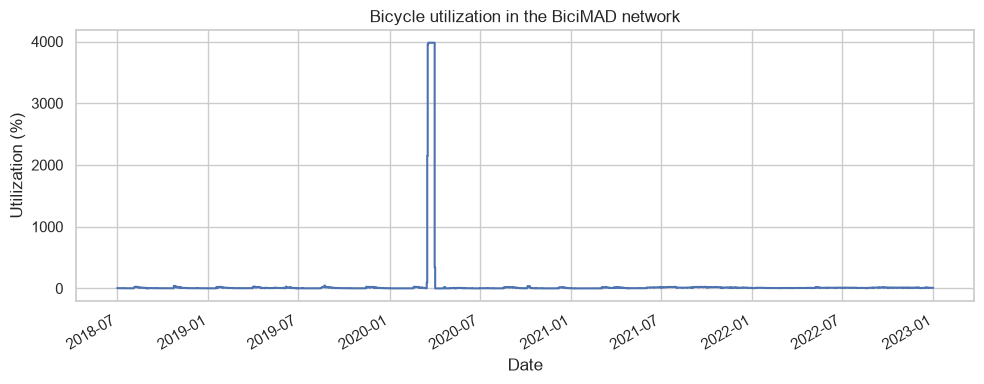

months used: 54 (2018-07 to 2022-12)
months inside that span without both files: none
plotted days: 1,630
gap days: 2018-08-03, 2019-06-14, 2019-07-09, 2019-08-15, 2019-08-16, 2019-08-26, 2019-09-01, 2019-11-14, 2020-07-16, 2021-05-19, 2021-11-23, 2022-06-20, 2022-09-23, 2022-10-12, 2022-12-17, 2023-01-01
first day 2018-07-01: 4.81%
last day 2022-12-31: 9.33%
minimum 0.00% on 2018-08-30
maximum 3980.00% on 2020-03-19
median 7.36%
year 2018: median 4.03% over 183 days
year 2019: median 5.28% over 358 days
year 2020: median 2.98% over 365 days
year 2021: median 12.82% over 363 days
year 2022: median 9.62% over 361 days
2020-03-17 to 2020-03-31: 15 days, min 2149.21%, max 3980.00%
2020-04-01 to 2020-04-01: 1 day, min 337.07%, max 337.07%
2020-04-02 to 2020-04-18: 17 days, min 0.00%, max 0.00%
2018-08-30 to 2018-08-31: 2 days, min 0.00%, max 0.00%
2019-06-27 to 2019-06-30: 4 days, min 0.00%, max 0.06%
2020-06-16 to 2020-06-30: 15 days, min 0.00%, max 0.00%


In [4]:
import json

QUIET_HOUR = 5  # hour h* from the quiet-hour chart

months = discover_months(cfg)["both"]
if not months:
    raise RuntimeError("No month has both a status file and a trip file.")
status_files = discover_status_files(cfg)
trip_files = discover_trip_files(cfg)
cache_dir = cfg.processed_dir / "infrastructure" / "bicycle_snapshots"

frames = []
for month in months:
    status_path = status_files[month]
    trip_path = trip_files[month]
    cache = cache_dir / f"{month}.parquet"
    manifest_path = cache_dir / f"{month}.manifest.json"
    manifest = {
        "status": {"file": status_path.name, "bytes": status_path.stat().st_size},
        "trips": {"file": trip_path.name, "bytes": trip_path.stat().st_size},
    }
    if not cache.is_file() or not manifest_path.is_file():
        raise RuntimeError(
            f"{month}: bicycle snapshot cache is missing. Run the bicycle section first."
        )
    saved = json.loads(manifest_path.read_text(encoding="utf-8"))
    if saved != manifest:
        raise RuntimeError(
            f"{month}: bicycle snapshot cache is stale. Run the bicycle section first."
        )
    frames.append(pd.read_parquet(cache, columns=["ts", "n_riding", "n_docked"]))

snapshots = pd.concat(frames, ignore_index=True)
local = snapshots["ts"].dt.tz_convert(MADRID_TZ)
snapshots["date"] = local.dt.floor("D")
quiet = snapshots.loc[local.dt.hour.eq(QUIET_HOUR)]
daily_b = quiet.groupby("date")["n_docked"].median()
snapshots["n_bikes"] = snapshots["date"].map(daily_b)
daily = daily_presence_utilization(
    snapshots,
    tz=MADRID_TZ,
    max_gap=pd.Timedelta(hours=6),
)
calendar = pd.date_range(
    snapshots["date"].min(), snapshots["date"].max(), freq="D", tz=MADRID_TZ
)
plot = daily.set_index("date").reindex(calendar)
fleet = daily_b.reindex(calendar)
eligible = plot["covered_hours"].ge(12) & fleet.gt(0)
rate = plot["utilization"].where(eligible)

fig, ax = plt.subplots()
ax.step(rate.index.tz_localize(None), 100 * rate, where="post")
ax.set_title("Bicycle utilization in the BiciMAD network")
ax.set_xlabel("Date")
ax.set_ylabel("Utilization (%)")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

present = rate.dropna()
pct = 100 * present
gaps = [ts.strftime("%Y-%m-%d") for ts in rate.index[rate.isna()]]
span = pd.period_range(months[0], months[-1], freq="M")
inside_missing = [str(period) for period in span if str(period) not in set(months)]
print(f"months used: {len(months)} ({months[0]} to {months[-1]})")
print("months inside that span without both files:", inside_missing or "none")
print(f"plotted days: {len(present):,}")
print("gap days:", ", ".join(gaps) if gaps else "none")
print(f"first day {present.index[0].strftime('%Y-%m-%d')}: {pct.iloc[0]:.2f}%")
print(f"last day {present.index[-1].strftime('%Y-%m-%d')}: {pct.iloc[-1]:.2f}%")
print(f"minimum {pct.min():.2f}% on {present.idxmin().strftime('%Y-%m-%d')}")
print(f"maximum {pct.max():.2f}% on {present.idxmax().strftime('%Y-%m-%d')}")
print(f"median {pct.median():.2f}%")
for year, group in pct.groupby(pct.index.year):
    print(f"year {year}: median {group.median():.2f}% over {len(group)} days")


def _window(start, end):
    sl = pct.loc[start:end]
    noun = "day" if len(sl) == 1 else "days"
    print(
        f"{start} to {end}: {len(sl)} {noun}, "
        f"min {sl.min():.2f}%, max {sl.max():.2f}%"
    )


_window("2020-03-17", "2020-03-31")
_window("2020-04-01", "2020-04-01")
_window("2020-04-02", "2020-04-18")
_window("2018-08-30", "2018-08-31")
_window("2019-06-27", "2019-06-30")
_window("2020-06-16", "2020-06-30")


The daily value of $U(D)$ starts at 4.81% on 1 July 2018 and the last plotted day is 9.33% on 31 December 2022. The median of the plotted days is 7.36%. The median within each year is 4.03% in 2018, 5.28% in 2019, 2.98% in 2020, 12.82% in 2021, and 9.62% in 2022.

From 17 March through 31 March 2020 the rate stays between 2,149.21% and 3,980.00%. The highest day is 3,980.00% on 19 March 2020. The numerator is still the open trips in the March file, while the denominator is the quiet-hour docked fleet of about 10 bicycles. On 1 April the rate is 337.07%, because the last March snapshot is held across midnight. From 2 April through 18 April the rate is 0.00%. That spike sets the scale of the chart, so the ordinary days sit near the axis.

The minimum is 0.00%, first reached on 30 August 2018. The August 2018 trip file stops on 29 August, and 30–31 August are 0.00% while the quiet-hour fleet is still present. The June 2019 file stops on 26 June, and from 27 June through 30 June the rate is at most 0.06%. The June 2020 file covers 1–15 June only, and from 16 June through 30 June the rate is 0.00%. Sixteen days are gaps. Fifteen have no snapshot in hour 05: 3 August 2018, 14 June 2019, 9 July 2019, 15 August 2019, 16 August 2019, 26 August 2019, 1 September 2019, 14 November 2019, 16 July 2020, 19 May 2021, 20 June 2022, 23 September 2022, 12 October 2022, 17 December 2022, and 1 January 2023. On 23 November 2021 the quiet-hour fleet is present, and the day is a gap because less than 12 hours of snapshots are bracketed. The series uses the same 54 months as the bicycle count, July 2018 through December 2022.
